In [ ]:
#install all the required dependancy libraries
#!pip install tensorflow #for prediction
#!pip install numpy  #for matrix multiplication
#!pip install pandas #define the data structures
#!pip install matplotlib #for visualization
#!pip install scikit-learn #for normalizing our data(scaling)

#importing the libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import io
%matplotlib inline


In [ ]:
#loading the dataset
from google.colab import files
uploaded = files.upload()

Saving data-bitcoin_timedata_v2.csv to data-bitcoin_timedata_v2.csv


In [ ]:
#decoding the files as uploaded will be a dictionary of keys (the file names) and values (the encoded file objects)
btc = pd.read_csv(io.StringIO(uploaded['data-bitcoin_timedata_v2.csv'].decode('utf-8')))
btc.head()

,date,open,high,low,close,number_of_trades
0,2017-08-17,4261.48,4485.39,4200.74,4285.08,3427
1,2017-08-18,4285.08,4371.52,3938.77,4108.37,5233
2,2017-08-19,4108.37,4184.69,3850.00,4139.98,2153
3,2017-08-20,4139.98,4211.08,4032.62,4086.29,2321
4,2017-08-21,4069.13,4119.62,3911.79,4016.00,3972


In [ ]:
#selecting only the column that we are going to use in the prediction process
data_to_use=btc['close'].values
data_to_use

array([ 4285.08,  4108.37,  4139.98, ..., 29281.09, 29232.25, 28902.49])

In [ ]:
# Definindo separação de dados:
separate_data = round(len(data_to_use)*0.8)
print("Total:", len(data_to_use))
print("80%:", separate_data)
print("20%:", len(data_to_use) - separate_data)

Total: 2176
80%: 1741
20%: 435


In [ ]:
# Separando dados de treino e teste:
train_data = data_to_use[:separate_data]
test_data = data_to_use[separate_data:]
print("Train data:", len(train_data))
print("Test data:", len(test_data))

Train data: 1741
Test data: 435


In [ ]:
#Normalizando dados:
scaler = MinMaxScaler()
scaler.fit(train_data.reshape(-1, 1))

train_data_normalized = scaler.transform(train_data.reshape(-1, 1))
test_data_normalized = scaler.transform(test_data.reshape(-1, 1))


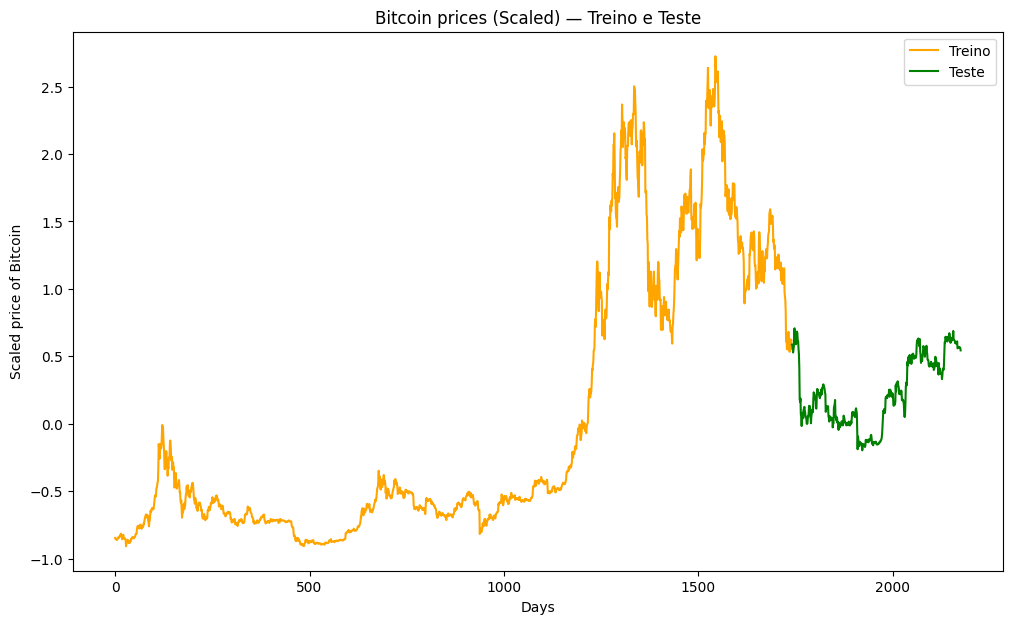

In [ ]:
# Plotando dados:
plt.figure(figsize=(12,7), frameon=False, facecolor='brown', edgecolor='blue')
plt.title('Bitcoin prices (Scaled) — Treino e Teste')
plt.xlabel('Days')
plt.ylabel('Scaled price of Bitcoin')

plt.plot(range(len(train_data_normalized)), train_data_normalized, label='Treino', color='orange')
plt.plot(range(len(train_data_normalized), len(train_data_normalized) + len(test_data_normalized)), test_data_normalized, label='Teste', color='green')

plt.legend()
plt.show()

In [ ]:
# Hyperparametros:
batch_size = 7
window_size = 7
hidden_layer = 256
learning_rate = 0.001
epochs = 100
clip_margin = 4

In [ ]:
# This function is used to create Features and Labels datasets. By windowing the data.
#Input: data - dataset used in the project
#window_size - how many data points we are going to use to predict the next datapoint in the sequence
#[Example: if window_size = 1 we are going to use only the previous day to predict todays stock prices]
#Outputs: X - features splitted into windows of datapoints (if window_size = 1, X = [len(data)-1, 1])
#y - 'labels', actually this is the next number in the sequence, this number we are trying to predict

def window_data(data, window_size):
    X = []
    y = []

    i = 0
    while (i + window_size) <= len(data) - 1:
        X.append(data[i:i+window_size])
        y.append(data[i+window_size])

        i += 1
    assert len(X) ==  len(y)
    return np.array(X), np.array(y)

#windowing the data with window_data function
X_train, y_train = window_data(train_data_normalized, window_size)
X_test, y_test = window_data(test_data_normalized, window_size)

print("X_train size: {}".format(X_train.shape))
print("y_train size: {}".format(y_train.shape))
print("X_test size: {}".format(X_test.shape))
print("y_test size: {}".format(y_test.shape))

X_train size: (1734, 7, 1)
y_train size: (1734, 1)
X_test size: (428, 7, 1)
y_test size: (428, 1)


In [ ]:
# Converter para float32 para evitar erro de tipo
X_train = X_train.astype(np.float32)
y_train = y_train.astype(np.float32)
X_test = X_test.astype(np.float32)
y_test = y_test.astype(np.float32)

In [ ]:
# INITIALIZE WEIGHTS:
initializer = tf.random.truncated_normal

#Weights for the input gate
weights_input_gate = tf.Variable(initializer([1, hidden_layer], stddev=0.05))
weights_input_hidden = tf.Variable(initializer([hidden_layer, hidden_layer], stddev=0.05))
bias_input = tf.Variable(tf.zeros([hidden_layer]))

#weights for the forgot gate
weights_forget_gate = tf.Variable(initializer([1, hidden_layer], stddev=0.05))
weights_forget_hidden = tf.Variable(initializer([hidden_layer, hidden_layer], stddev=0.05))
bias_forget = tf.Variable(tf.zeros([hidden_layer]))

#weights for the output gate
weights_output_gate = tf.Variable(initializer([1, hidden_layer], stddev=0.05))
weights_output_hidden = tf.Variable(initializer([hidden_layer, hidden_layer], stddev=0.05))
bias_output = tf.Variable(tf.zeros([hidden_layer]))

#weights for the memory cell
weights_memory_cell = tf.Variable(initializer([1, hidden_layer], stddev=0.05))
weights_memory_cell_hidden = tf.Variable(initializer([hidden_layer, hidden_layer], stddev=0.05))
bias_memory_cell = tf.Variable(tf.zeros([hidden_layer]))

#Output layer weigts
weights_output_layer = tf.Variable(initializer([hidden_layer, 1], stddev=0.05))
bias_output_layer = tf.Variable(tf.zeros([1]))

In [ ]:
# LSTM CELL:
def LSTM_cell(input, output, state):
    input_gate = tf.sigmoid(tf.matmul(input, weights_input_gate) + tf.matmul(output, weights_input_hidden) + bias_input)
    forget_gate = tf.sigmoid(tf.matmul(input, weights_forget_gate) + tf.matmul(output, weights_forget_hidden) + bias_forget)
    output_gate = tf.sigmoid(tf.matmul(input, weights_output_gate) + tf.matmul(output, weights_output_hidden) + bias_output)
    memory_cell = tf.tanh(tf.matmul(input, weights_memory_cell) + tf.matmul(output, weights_memory_cell_hidden) + bias_memory_cell)
    state = state * forget_gate + input_gate * memory_cell
    output = output_gate * tf.tanh(state)
    return state, output

In [ ]:
# FORWARD PASS:
def forward_pass(inputs):
    outputs = []
    for i in range(inputs.shape[0]):  # Iterate over batch
        batch_state = tf.zeros([1, hidden_layer], dtype=tf.float32)
        batch_output = tf.zeros([1, hidden_layer], dtype=tf.float32)
        for ii in range(window_size):
            inp = tf.reshape(inputs[i][ii], (1, 1))
            batch_state, batch_output = LSTM_cell(inp, batch_output, batch_state)
        outputs.append(tf.matmul(batch_output, weights_output_layer) + bias_output_layer)
    return tf.concat(outputs, axis=0)

In [ ]:
# TRAINING LOOP:
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

for epoch in range(epochs):
    epoch_loss = []
    train_scores = []

    for ii in range(0, len(X_train) - batch_size + 1, batch_size):
        X_batch = X_train[ii:ii + batch_size]
        y_batch = y_train[ii:ii + batch_size]

        with tf.GradientTape() as tape:
            preds = forward_pass(X_batch)
            loss = tf.reduce_mean((preds - y_batch) ** 2)

        gradients = tape.gradient(loss, [weights_input_gate, weights_input_hidden, bias_input,
                                         weights_forget_gate, weights_forget_hidden, bias_forget,
                                         weights_output_gate, weights_output_hidden, bias_output,
                                         weights_memory_cell, weights_memory_cell_hidden, bias_memory_cell,
                                         weights_output_layer, bias_output_layer])

        gradients = [tf.clip_by_value(g, -clip_margin, clip_margin) for g in gradients]
        optimizer.apply_gradients(zip(gradients, [weights_input_gate, weights_input_hidden, bias_input,
                                                  weights_forget_gate, weights_forget_hidden, bias_forget,
                                                  weights_output_gate, weights_output_hidden, bias_output,
                                                  weights_memory_cell, weights_memory_cell_hidden, bias_memory_cell,
                                                  weights_output_layer, bias_output_layer]))

        epoch_loss.append(loss.numpy())
        train_scores.append(preds.numpy())

    if (epoch % 5) == 0:
        print(f"Epoch {epoch}/{epochs}, Current loss: {np.mean(epoch_loss):.4f}")

Epoch 0/100, Current loss: 0.0641
Epoch 5/100, Current loss: 0.0537
Epoch 10/100, Current loss: 0.0141
Epoch 15/100, Current loss: 0.0108
Epoch 20/100, Current loss: 0.0097
Epoch 25/100, Current loss: 0.0065
Epoch 30/100, Current loss: 0.0084
Epoch 35/100, Current loss: 0.0063
Epoch 40/100, Current loss: 0.0062
Epoch 45/100, Current loss: 0.0059
Epoch 50/100, Current loss: 0.0054
Epoch 55/100, Current loss: 0.0053
Epoch 60/100, Current loss: 0.0051
Epoch 65/100, Current loss: 0.0050
Epoch 70/100, Current loss: 0.0049
Epoch 75/100, Current loss: 0.0048
Epoch 80/100, Current loss: 0.0047
Epoch 85/100, Current loss: 0.0046
Epoch 90/100, Current loss: 0.0046
Epoch 95/100, Current loss: 0.0045


In [ ]:
print("Final loss:", loss.numpy())

Final loss: 0.0042043733


In [ ]:
# TRAIN PREDICTIONS:
train_predictions = forward_pass(X_train)
print("Predictions shape:", train_predictions.shape)

# Converter o tensor para numpy antes de transformar em lista
train_predictions_list = train_predictions.numpy().flatten().tolist()

# Converte para valores reais
train_predictions_real = scaler.inverse_transform(np.array(train_predictions_list).reshape(-1, 1)).flatten().tolist()

Predictions shape: (1734, 1)


In [ ]:
# TEST PREDICTIONS:
test_predictions = forward_pass(X_test)
print("Predictions shape:", test_predictions.shape)

# Converter o tensor para numpy antes de transformar em lista
test_predictions_list = test_predictions.numpy().flatten().tolist()

# Converte para valores reais
test_predictions_real = scaler.inverse_transform(np.array(test_predictions_list).reshape(-1, 1)).flatten().tolist()

Predictions shape: (428, 1)


In [ ]:
# AJUSTE DOS RESULTADOS PARA PLOTAR (valores normalizados):
# Total de amostras: treino + teste
total_length = len(train_predictions_list + test_predictions_list)

# Lista final de resultados contínuos (None onde não há previsão)
train_results = []
test_results = []
for i in range(total_length):
    if i < len(train_predictions_list):
        train_results.append(train_predictions_list[i])
        test_results.append(None)
    else:
      train_results.append(None)
      test_index = i - len(train_predictions_list)
      test_results.append(test_predictions_list[test_index])

# Normaliza dados originais:
data_to_use_normalized = scaler.transform(data_to_use.reshape(-1, 1))

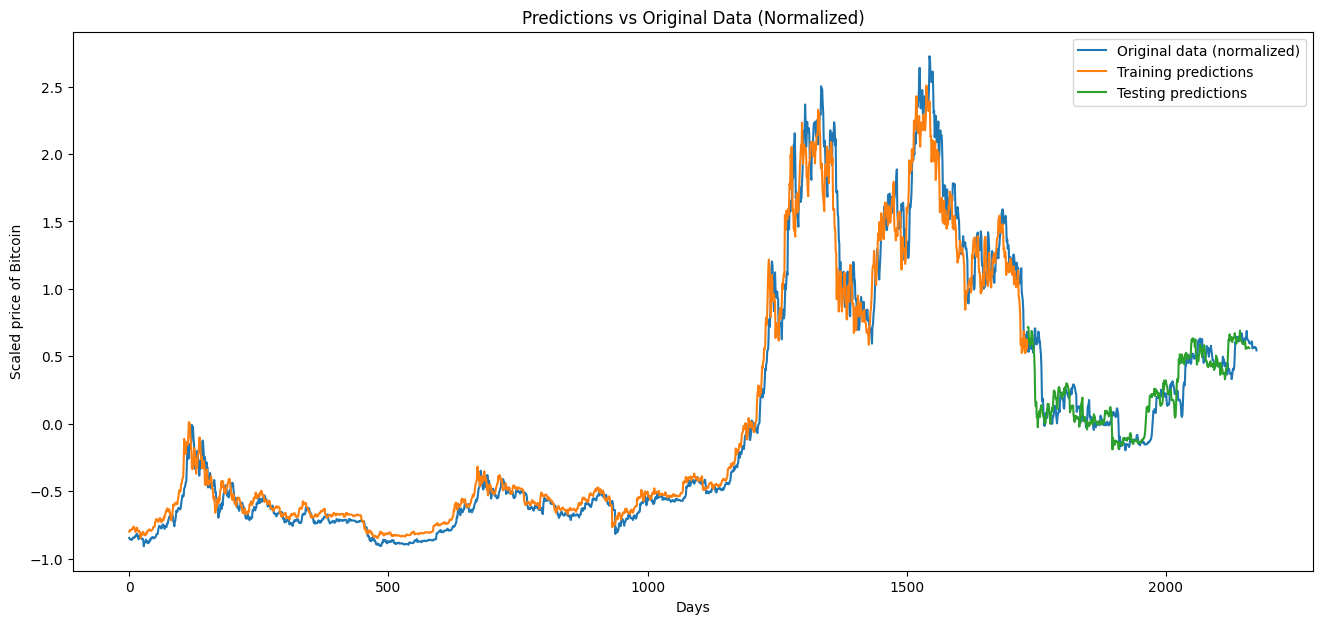

In [ ]:
# PLOT RESULTADOS NORMALIZADOS
plt.figure(figsize=(16,7))
plt.plot(data_to_use_normalized, label='Original data (normalized)')
plt.plot(train_results, label='Training predictions')
plt.plot(test_results, label='Testing predictions')
plt.title('Predictions vs Original Data (Normalized)')
plt.xlabel('Days')
plt.ylabel('Scaled price of Bitcoin')
plt.legend()
plt.show()

In [ ]:
# AJUSTE DOS RESULTADOS PARA PLOTAR (valores reais):
# Total de amostras: treino + teste
total_length = len(train_predictions_real + test_predictions_real)

# Lista final de resultados contínuos (None onde não há previsão)
train_results_real = []
test_results_real = []
for i in range(total_length):
    if i < len(train_predictions_real):
        train_results_real.append(train_predictions_real[i])
        test_results_real.append(None)
    else:
      train_results_real.append(None)
      test_index = i - len(train_predictions_real)
      test_results_real.append(test_predictions_real[test_index])

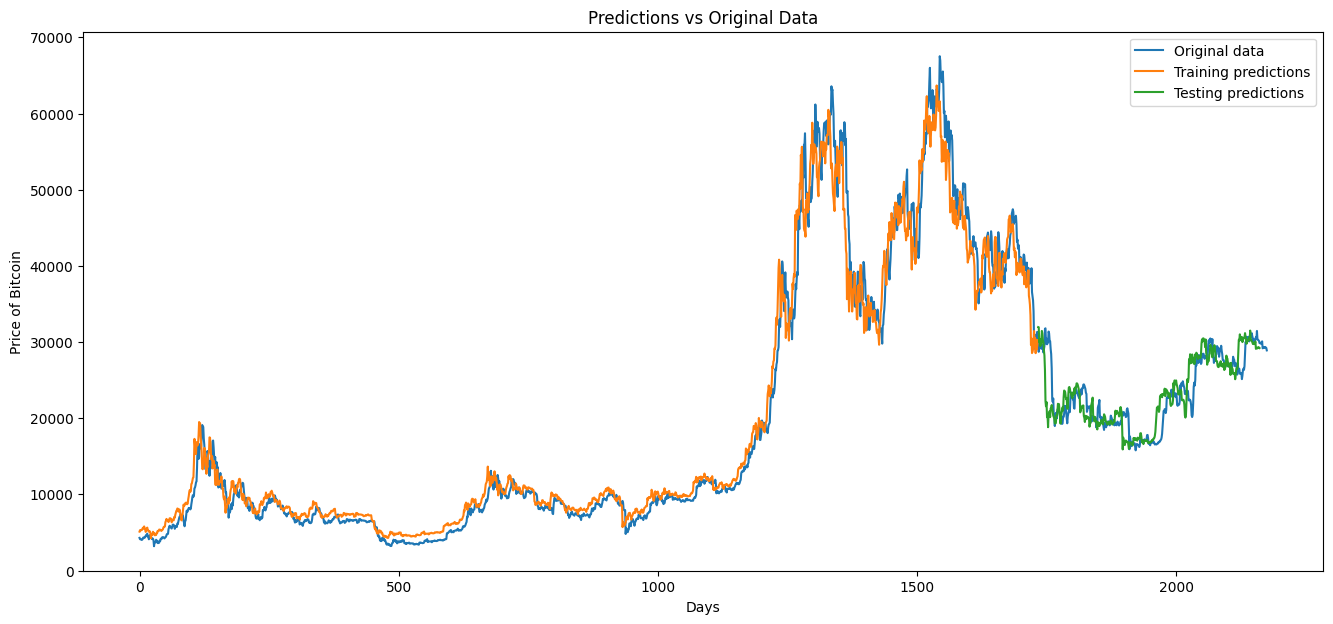

In [ ]:
# PLOT RESULTADOS REAIS:
plt.figure(figsize=(16,7))
plt.plot(data_to_use, label='Original data')
plt.plot(train_results_real, label='Training predictions')
plt.plot(test_results_real, label='Testing predictions')
plt.title('Predictions vs Original Data')
plt.xlabel('Days')
plt.ylabel('Price of Bitcoin')
plt.legend()
plt.show()

In [ ]:
target_values = y_test.flatten().tolist()
predicted_values = test_predictions_list

In [ ]:
# Exemplo: y_test_original e y_pred_original já revertidos do scaler
mse = mean_squared_error(target_values, predicted_values)
rmse = np.sqrt(mse)
mae = mean_absolute_error(target_values, predicted_values)
r2 = r2_score(target_values, predicted_values)

def pocid(y_true, y_pred):
    correct_dir = np.sum(np.sign(np.diff(y_true)) == np.sign(np.diff(y_pred)))
    total = len(y_true) - 1
    return 100 * correct_dir / total

pocid_val = pocid(target_values, predicted_values)

print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")
print(f"POCID: {pocid_val:.2f}%")


MSE: 0.0014
RMSE: 0.0373
MAE: 0.0258
R²: 0.9784
POCID: 47.54%
